# 10.1.4 Escoamento horizontal via modelo a 3 equações (Beggs & Brill)

Mesmo cenário de 10.1.1 (qG de 0.1 para 0.13 kg/s) com o modelo de mistura
baseado nas correlações de Beggs & Brill (capítulo 6). Figura 10.17.

**Nota de reprodução.** O estado gravado no arquivo original é estacionário
para o modelo de Beggs & Brill com identificação automática de padrão
(transição estratificado/intermitente), mas o gradiente de pressão gravado
(0.084 Pa/m) é cerca de 130 vezes menor do que o produzido pela versão final
do código `modelo_duto_BB.m` (10.7 Pa/m, fator de atrito de Churchill com
correção bifásica de Beggs & Brill). Ou seja, a figura 10.17 da tese foi
gerada com uma versão anterior do fechamento de atrito. Aqui o caso é
resolvido com o modelo final: calculamos o estado estacionário consistente e
simulamos o mesmo cenário; os resultados do MATLAB são mostrados apenas para
referência qualitativa.

In [1]:
import copy, numpy as np, matplotlib.pyplot as plt
from mfsim.notebook_utils import describe, run_case, compare_states, show_pipe
from mfsim.cases import load_chapter10_case
from mfsim.simulation import steady_state, simulate
from mfsim.plotting import pipe_surfaces, pipe_timeseries, legacy_pipe_dict

describe("10.1.4")
case, raw = load_chapter10_case("10.1.4")
print("regime do duto:", case.pipes[0].regime, "(6 = identificação automática)")

10.1.4 Escoamento horizontal via modelo a 3 equações
Cenário de 10.1.1 com o modelo de mistura (Beggs & Brill).
Figuras da tese: Fig. 10.17
regime do duto: 6 (6 = identificação automática)


## Estado inicial gravado (MATLAB) vs. resíduo do modelo final

In [2]:
from mfsim.simulation import build_model
from mfsim.io_legacy import legacy_states

Tl, Xl = legacy_states(raw)
model = build_model(case)
r = model.rhs(0.0, Xl[:, 0])
slots = model.state_slots()
print(
    "resíduo |dX/dt| no estado gravado, por variável:",
    {n: f"{np.max(np.abs(r[slots == s])):.2e}" for s, n in [(1, "PT"), (2, "qL"), (3, "qG")]},
)

resíduo |dX/dt| no estado gravado, por variável: {'PT': '2.89e-13', 'qL': '7.64e-02', 'qG': '7.17e-03'}


## Estado estacionário consistente e simulação dinâmica

estado estacionário: convergiu = True  resíduo = 5.60e-10


[implicit BDF] steps=290 rejected=15 rhs=9001 jac=146 | 6.7s
pressão de entrada (bar): 100.107126193036  fração de gás média: 0.0


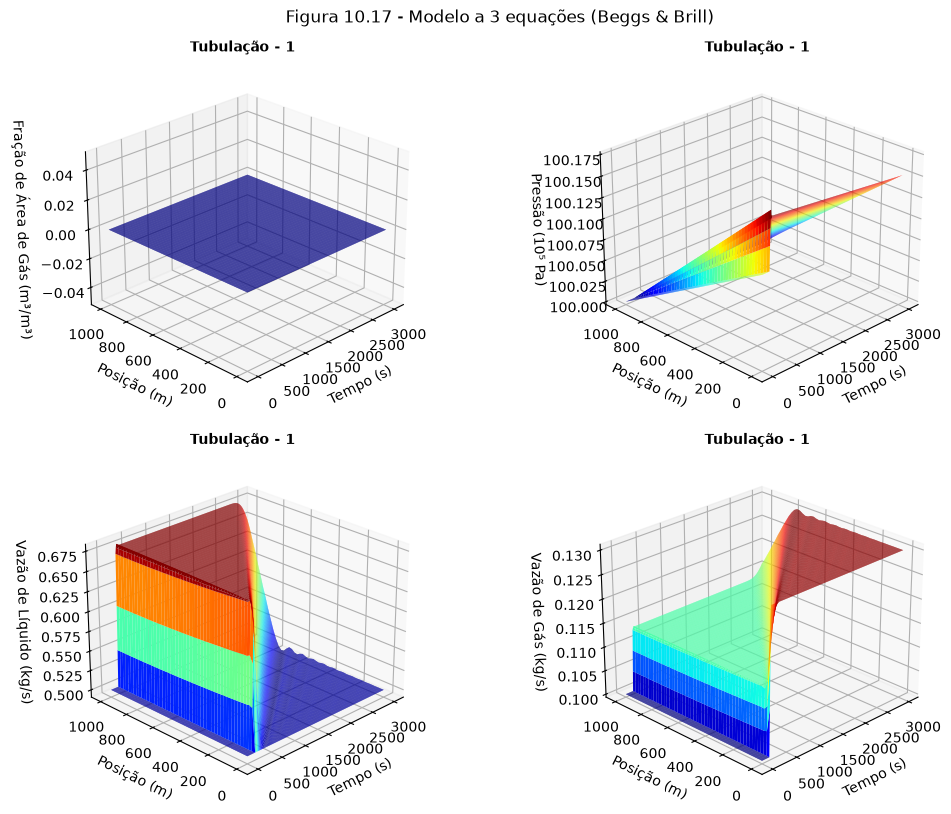

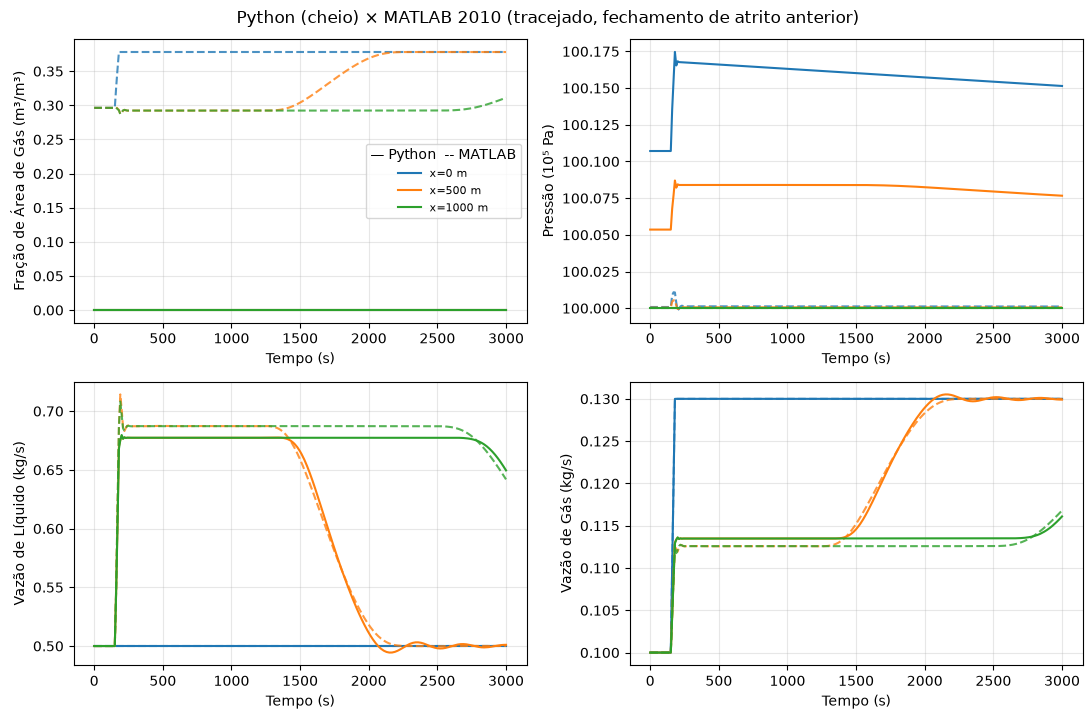

In [3]:
case_ss = copy.deepcopy(case)
n = case_ss.pipes[0].n_elements[0] + 1
case_ss.pipes[0].ic = np.stack([np.full(n, 0.3), np.full(n, 1.0), np.full(n, 0.5), np.full(n, 0.1)], axis=1)
model_ss, X_ss, info_ss = steady_state(case_ss, verbose=False)
print("estado estacionário: convergiu =", info_ss["converged"], " resíduo =", f"{info_ss['residual']:.2e}")
res = simulate(case_ss, integrator="implicit", rtol=1e-4, atol=1e-6, max_step=np.inf)
p = res.pipe(0)
print("pressão de entrada (bar):", p["out"]["P_bar"][0, 0], " fração de gás média:", p["out"]["alphaG"][:, 0].mean())
fig = pipe_surfaces(res, 0)
fig.suptitle("Figura 10.17 - Modelo a 3 equações (Beggs & Brill)", y=1.02)
plt.show()
fig = pipe_timeseries(res, 0, legacy=legacy_pipe_dict(raw, 0))
fig.suptitle("Python (cheio) × MATLAB 2010 (tracejado, fechamento de atrito anterior)", y=1.02)
plt.show()

## Lado direito compilado (JAX)
A mesma simulação com `simulate(..., jax=True)`: lado direito compilado por
`jax.jit` e Jacobiana exata por diferenciação automática (`mfsim/compiled.py`, o mesmo código numpy com o backend JAX),
no lugar das diferenças finitas coloridas. O resultado deve coincidir com a versão
numpy dentro da tolerância do integrador (as sequências de passos podem diferir
porque a Jacobiana muda o Newton); o ganho de tempo cresce com o número de passos
e de Jacobianas.

In [4]:
from mfsim.notebook_utils import jax_comparison

res_jax = jax_comparison(case_ss, res, rtol=1e-4, atol=1e-6)

JAX: 1.93 s (290 passos; compilação 0.79 s, uma vez por modelo) | numpy: 6.72 s (290 passos) | diferença máxima relativa dos estados 7.7e-04
